# AV Validation Gap: 17 · Disengagement risk per mile, by place

**The reframing (14 Oct).** A staff engineer's feedback, via Nithya: frame the product as
*predicting disengagement risk*, not predicting disengagements. Make it useful to engineers for
spotting **tricky terrain**. Predict at **road-segment or grid-cell level**, then **display at city or
county level**. Report **risk per mile with its uncertainty and sample size**. If there is time, use
**several specialised models that feed one aggregated risk**.

Malachi's dashboard (github.com/scobi7/AVDashboard) already scores tracts by road-type mix. This
notebook is its third revision. What the DMV data can and cannot support:

| | in the DMV files? |
|---|---|
| reports per company per month | yes (52,626 reports with a road box, 39 companies, 2020–24 reporting years) |
| autonomous miles per company per month | yes (mileage reports, per vehicle) |
| road type of each report | a box: Street, Freeway, Highway, Interstate, Rural Road, Parking Facility |
| where each report happened | **no** (no coordinates, no street) |
| miles per road type | **no** |
| what the car was handling | sometimes, in the free-text description |

Three questions follow:

1. **Per mile driven, are freeway-type roads riskier than surface streets?** Revision 2 said
   freeways see 5.4× their share. That used road length as a stand-in for miles.
2. **Which road situations do the reports name, and where are those situations?** Local LLMs read every
   description; each situation becomes a specialised model tied to an OpenStreetMap feature.
3. **Does the resulting map mark places where AVs actually struggle?** Disengagements can't be
   located, so the check uses located AV collisions, which played no part in building the map.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
import avgap_disengage as D, avgap_data as A, avgap_llm as L
from avgap_style import C as COL, INK, INK2, MUTED, new_ax, finish
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
fit = D.fit_all()          # cached in av_data/disengage/fit_v3.pkl (python avgap_disengage.py fit rebuilds it)
res = D.score_all(fit)     # writes the dashboard's CSVs to outputs/
cells, terr, stretches = D.terrain()
print(f"reports with a road box: {len(fit['report_table']):,} from {fit['report_table'].company.nunique()} companies; "
      f"freeway-type {fit['reports_by_class']['freeway']:,}, surface {fit['reports_by_class']['surface']:,}")

reports with a road box: 52,626 from 39 companies; freeway-type 9,825, surface 42,801


## 1 · The per-mile base: companies differ by orders of magnitude

Every company files its autonomous miles, so a company's reports per mile is a real rate. The spread
between companies dwarfs anything about place.

2024: 15 companies with 1,000+ autonomous miles; reports per 1,000 miles: median 0.50, lowest 0.000 (AutoX), highest 1,488 (May Mobility)
pooled 2024 rate (every report / every mile): 7.51 per 1,000 miles; May Mobility alone files 73% of 2024 reports
median company rate by year: {2019: 0.446, 2020: 0.616, 2021: 0.579, 2022: 0.148, 2023: 0.39, 2024: 0.496}


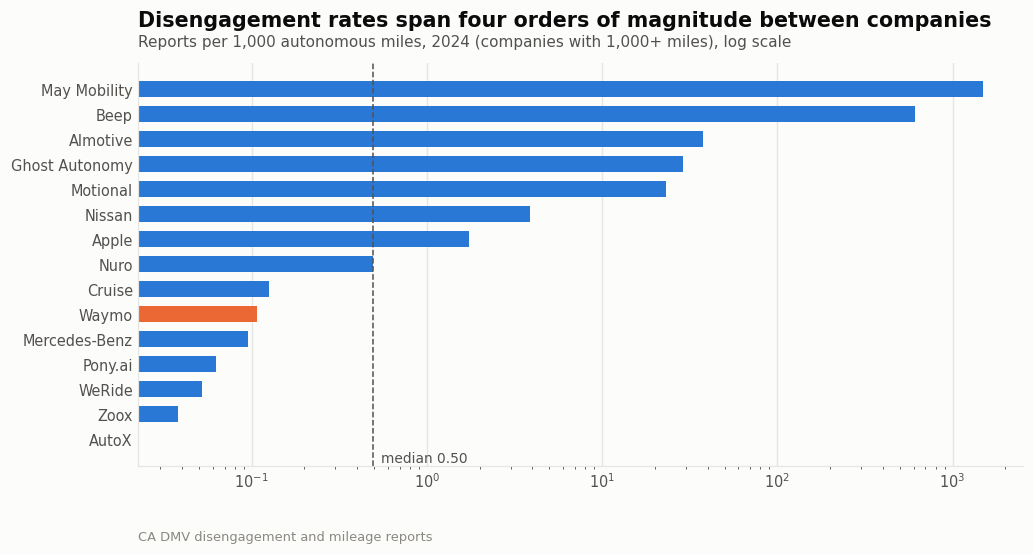

In [2]:
r = fit["rates"]
y24 = r[r.year == 2024].sort_values("per_1k_miles")
print(f"2024: {len(y24)} companies with 1,000+ autonomous miles; reports per 1,000 miles: median "
      f"{y24.per_1k_miles.median():.2f}, lowest {y24.per_1k_miles.min():.3f} ({y24.iloc[0].company}), "
      f"highest {y24.per_1k_miles.max():,.0f} ({y24.iloc[-1].company})")
pooled = y24.reports.sum() / y24.miles.sum() * 1000
print(f"pooled 2024 rate (every report / every mile): {pooled:.2f} per 1,000 miles; "
      f"May Mobility alone files {y24.set_index('company').reports.get('May Mobility', 0) / y24.reports.sum():.0%} of 2024 reports")
by_year = r.groupby("year").per_1k_miles.median()
print("median company rate by year:", by_year.round(3).to_dict())
fig, ax = new_ax(9.5, 5.2)
ax.barh(y24.company, y24.per_1k_miles, color=[COL["orange"] if c == "Waymo" else COL["blue"] for c in y24.company], height=0.65)
ax.set_xscale("log"); ax.axvline(fit["reference_rate"], color=INK2, lw=1, ls="--")
ax.text(fit["reference_rate"] * 1.1, -0.9, f"median {fit['reference_rate']:.2f}", color=INK2, fontsize=9)
finish(ax, "Disengagement rates span four orders of magnitude between companies",
       "Reports per 1,000 autonomous miles, 2024 (companies with 1,000+ miles), log scale",
       source="CA DMV disengagement and mileage reports", save="DIS_01_company_rates.png")

In 2024 the 15 companies with 1,000+ autonomous miles filed between none (AutoX) and 1,488 reports per
1,000 miles (May Mobility); the median company filed 0.50. Pooling every report over every mile gives 7.51,
and May Mobility files 73% of 2024's reports. So a pooled base rate measures one company.

The map therefore reports a **relative risk per mile** (1.0 = an average California road mile). It converts
that to reports per 1,000 miles at the **median company's 2024 rate (0.50)**. Revision 2's base rate (2,519
per million miles) was the pooled 2020–24 rate. The relative index does not depend on which company sets
the scale.

## 2 · Freeway or surface: what is the rate per mile?

The ratio of the freeway-type rate per mile to the surface rate per mile is the one road-type number the
data can speak to. The DMV form has no arterial box: "Street" covers every surface road, and companies use
"Highway" for freeway driving, so there are two classes (revision 2's mapping). Three ways to estimate it:

- **road-length exposure** (revision 2): a company's miles are split like California's road length
  (7.6% freeway-type);
- **vehicle-mile exposure**: its miles are split like all California traffic. FHWA's Highway Statistics
  table VM-2 for 2023 has freeway-type roads (Interstate plus other freeways and expressways) carrying
  48% of vehicle-miles;
- **filed miles, within company** (new): no exposure assumption. In a month when a company files more of
  its reports on freeways, its miles were more freeway-heavy. If freeway miles produce reports at a
  different rate, that month's total reports per mile move with the freeway share:
  E[reports] = miles × L / (1 − p (1 − 1/ρ)), where p is the month's freeway share of reports. The
  model is a negative-binomial GLM with a level for each company-year, profiled over ρ.

In [3]:
ex = fit["exposure"].copy()
ex.loc["filed miles, within company (revision 3)", "freeway share of exposure"] = np.nan
print(ex.round(3).to_string())
f = fit["forms"]
for k, v in f.items():
    print(f"filed miles, levels by {k:13s}: rho {v['rho']:.2f} (profile 95% {v['lo']:.2f}-{v['hi']:.2f}), "
          f"{v['companies']} companies, {v['months']} company-months, {v['reports']:,} reports")

                                          freeway share of exposure  freeway / surface rate per mile
road length (OSM), revision 2                                 0.075                            7.985
vehicle-miles (FHWA VM-2 2023)                                0.479                            0.708
filed miles, within company (revision 3)                        NaN                            0.721
filed miles, levels by company-year : rho 0.72 (profile 95% 0.47-1.13), 10 companies, 316 company-months, 17,216 reports
filed miles, levels by company      : rho 0.47 (profile 95% 0.29-0.78), 10 companies, 316 company-months, 17,216 reports
filed miles, levels by company trend: rho 0.42 (profile 95% 0.29-0.61), 10 companies, 316 company-months, 17,216 reports


In [4]:
byc = fit["by_company"]
print(byc.round(2).to_string())
re_ = fit["random_effects"]
print(f"\nrandom-effects pool of the {re_['companies']} companies with a usable interval ({', '.join(re_['used'])}): "
      f"rho {re_['rho']:.2f} (95% {re_['lo']:.2f}-{re_['hi']:.2f}), between-company sd of log rho {re_['tau']:.2f}, "
      f"prediction interval for a new company {re_['pred_lo']:.2f}-{re_['pred_hi']:.2f}")
print("\nleave one company out:")
print(fit["loco"].round(2).to_string(index=False))

          company  months  reports  freeway share of reports  sd of monthly freeway share    rho    lo      hi  at grid edge
0           Apple      50    10254                      0.54                         0.44   0.98  0.46    2.51         False
1  Ghost Autonomy      21     1833                      0.98                         0.07   0.42  0.01    5.41          True
2        AImotive      51     1795                      0.76                         0.31   0.14  0.04    0.34         False
3   Mercedes-Benz      48     1481                      0.06                         0.11   1.18  0.29    4.64         False
4           Waymo      58      939                      0.24                         0.27   1.64  0.54    5.41         False
5           Bosch      16      391                      0.19                         0.09   2.05  0.54  100.00          True
6          NVIDIA      35      214                      0.61                         0.25   0.26  0.01    8.58          True


**The exposure assumption decides the answer.** Revision 2's own model gives freeway-type roads 7.99× the
surface rate per mile under road-length exposure, but 0.71× under vehicle-mile exposure. Freeway-type roads
are 7.5% of California's road length but carry 47.9% of its vehicle-miles. Filed miles, with no split
assumed, give 0.72 (profile 95% 0.47–1.13) with company-year levels; 0.47 with company levels only; 0.42
with company trends.

Companies differ. Apple (0.98), Mercedes-Benz (1.18), Waymo (1.64) and Aurora (1.65) sit at or above 1,
and AImotive at 0.14. The random-effects pool of the six companies with a usable interval is 1.08
(0.41–2.83), with a between-company sd of 1.0 on the log scale. Leaving out any one company gives 0.61–0.79,
except that without AImotive the estimate is 1.10 (0.69–1.87).

### Is the estimator right? A simulation with known answers

Before trusting a new estimator, it is run on synthetic panels where the true ratio is known. These keep
the real company-months, miles and dispersion, and add negative-binomial noise in two structures: one shock
per month shared by both road classes, or separate shocks per class. The real data can't say which
structure holds.

                      median   q05   q95  coverage
noise       true rho                              
common      0.10        0.49  0.35  0.75      0.00
            0.15        0.50  0.34  0.71      0.00
            0.25        0.63  0.40  0.97      0.00
            0.35        0.69  0.57  1.12      0.00
            0.50        0.73  0.55  1.16      0.52
            0.70        0.80  0.57  1.13      0.82
            1.00        0.96  0.71  1.43      0.95
            1.40        1.16  0.79  1.62      0.68
            2.00        1.42  1.01  2.16      0.60
            2.80        1.73  1.17  2.46      0.52
            4.00        1.89  1.35  3.08      0.10
            8.00        2.66  1.89  5.00      0.12
independent 0.10        0.39  0.28  0.53      0.00
            0.15        0.44  0.32  0.66      0.00
            0.25        0.51  0.39  0.75      0.02
            0.35        0.55  0.43  0.76      0.05
            0.50        0.63  0.49  0.85      0.72
            0.70        0.71  0

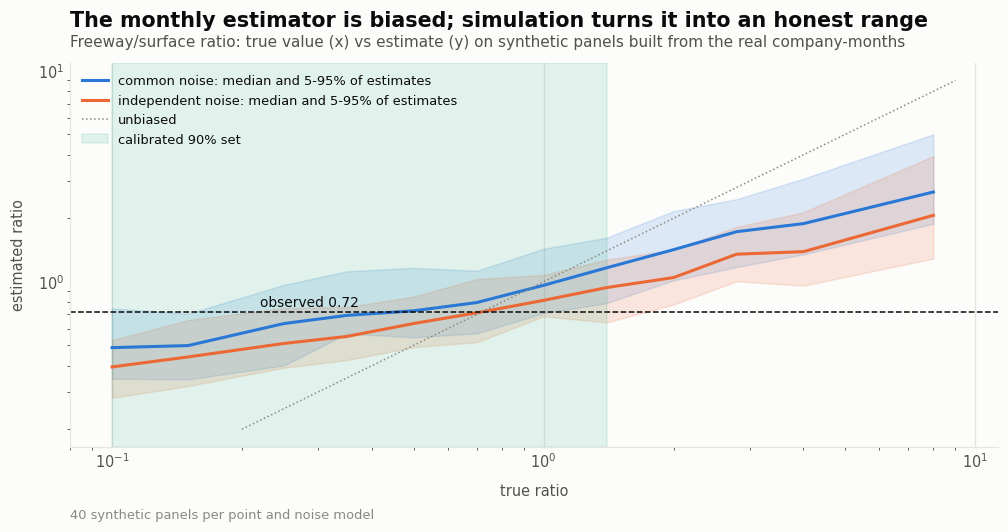

In [5]:
summ = fit["sim_summary"]
print(summ.round(2).to_string())
cs = fit["confidence_set"]
print(f"\nobserved estimate {fit['rho_estimate']:.2f}. Simulation-calibrated 90% set (true ratios whose simulated "
      f"5-95% band contains it): {cs['lo']:.2f} to {cs['hi']:.2f}")
print(cs["by_noise"])
fig, ax = new_ax(9.5, 5.0)
for (noise, g), col in zip(summ.reset_index().groupby("noise"), [COL["blue"], COL["orange"]]):
    ax.fill_between(g["true rho"], g.q05, g.q95, color=col, alpha=0.15)
    ax.plot(g["true rho"], g["median"], color=col, lw=2, label=f"{noise} noise: median and 5-95% of estimates")
ax.plot([0.2, 9], [0.2, 9], color=MUTED, lw=1, ls=":", label="unbiased")
ax.axhline(fit["rho_estimate"], color=INK, lw=1, ls="--"); ax.text(0.22, fit["rho_estimate"] * 1.06, f"observed {fit['rho_estimate']:.2f}", fontsize=9)
ax.axvspan(cs["lo"], cs["hi"], color=COL["aqua"], alpha=0.12, label="calibrated 90% set")
ax.set_xscale("log"); ax.set_yscale("log"); ax.legend(frameon=False, fontsize=8.5, loc="upper left")
finish(ax, "The monthly estimator is biased; simulation turns it into an honest range",
       "Freeway/surface ratio: true value (x) vs estimate (y) on synthetic panels built from the real company-months",
       xlabel="true ratio", ylabel="estimated ratio", source="40 synthetic panels per point and noise model",
       save="DIS_02_ratio_simulation.png")

**The estimator is biased, and its profile interval can't be trusted.** It is unbiased under pure Poisson
noise. But the real months are overdispersed, so it pulls estimates toward about 0.6–1.0: under independent
noise a true 2.0 comes back as 1.05, and a true 0.5 as 0.63. Away from 1, the profile intervals cover the
truth in 0–85% of panels.

The honest statement is the **simulation-calibrated 90% set**: every true ratio whose simulated estimates
bracket the observed 0.72. That set is **0.10–1.40** (0.10–1.0 with shared monthly shocks, where the lower
end is the grid edge; 0.25–1.4 with independent shocks). The median-unbiased point, where the simulated
median equals 0.72, is **0.58** (0.47 and 0.72 under the two noise models).

So **per mile driven, freeway-type roads are not riskier than surface streets.** A ratio of 2 or more never
produces an estimate as low as the one observed, under either noise model. Revision 2's 5.4× (8.0× in this
mapping) was per km of road, not per mile driven. The map uses 0.58, with draws spread over the calibrated
set.

## 3 · What the reports say about where

Each of the 1,513 distinct descriptions (covering every report) was read by two local open-weight LLMs,
**Qwen3.5-9B** and **Gemma 4 12B** (4-bit, letter-probability answers as in notebooks 09 and 15). They
answered two multiple-choice questions: the **road situation** the vehicle was handling (ten options) and
the **setting** (intersection, mid-block, freeway, parking, not stated). The two models' probabilities
are averaged.

Each situation tied to a mappable feature becomes a **specialised model**. Its rate per mile scales with
that feature's density, relative to California's average:

| situation | road class | feature | source |
|---|---|---|---|
| traffic control (lights, stop signs, rail crossings) | surface | signals + stop signs + level crossings per km | OSM nodes |
| turning or yielding at an intersection | surface | street-graph junctions (3+ ways) per km | OSM geometry |
| pedestrian or crosswalk | surface | marked crossings on the road per km | OSM nodes |
| cyclist, scooter, motorcyclist | surface | share of km with a bike lane | OSM tags |
| lane change or merge | surface | share of km with 4+ lanes | OSM tags |
| obstruction (double-parked or stopped vehicles, blocked lanes) | surface | shops, food and services per km (curbside activity) | OSM POIs |
| lane keeping | surface / freeway | road curvature, degrees of turn per km | OSM geometry |
| lane change or merge | freeway | share of km that is ramps | OSM tags |
| another vehicle's behaviour | freeway | traffic volume (AADT) | Caltrans Traffic Census, 14,072 count points |

Caltrans counts cover the state highway system only, so another vehicle's behaviour on surface streets
stays untied. Construction, and reports that name no situation, are spread evenly over every mile of their
class. The traffic count enters as a *feature*, not as exposure: AV test miles are not distributed like
human traffic.

In [6]:
from sklearn.metrics import cohen_kappa_score
lab = L.scen_labels(list(D.SCEN_MODELS))
it = L.items(); w = it.set_index("item_id").rows.astype(int)
rows = []
for q in ["situation", "setting"]:
    x = lab[lab.question == q].pivot(index="item_id", columns="variant", values="label").dropna()
    rows.append({"question": q, "texts": len(x), "agree": (x["q35-9b"] == x["g4-12b"]).mean(),
                 "kappa": cohen_kappa_score(x["q35-9b"], x["g4-12b"]),
                 "agree, weighted by reports": np.average(x["q35-9b"] == x["g4-12b"], weights=w.reindex(x.index))})
print(pd.DataFrame(rows).round(3).to_string(index=False))
sh = fit["shares"]
tab = pd.concat({h: sh[h].T for h in sh}, axis=1)
print("\nshare of each road class's reports in each situation")
print(tab.round(3).to_string())
tied_sf = {h: sh[h].loc["surface", [s for s in D.TIED if not s.endswith("(freeway)")]].sum() for h in sh}
tied_fw = {h: sh[h].loc["freeway", [D.situation_of(s) for s in D.TIED if s.endswith("(freeway)")]].sum() for h in sh}
print(f"\nsurface reports tied to a mappable feature: {tied_sf['stated']:.1%} as stated, {tied_sf['imputed']:.1%} if unnamed "
      f"non-fault reports follow the named mix; freeway reports: {tied_fw['stated']:.1%} to {tied_fw['imputed']:.1%}")

 question  texts  agree  kappa  agree, weighted by reports
situation   1513  0.781  0.735                       0.897
  setting   1513  0.695  0.469                       0.839

share of each road class's reports in each situation
                           stated         imputed        
                          freeway surface freeway surface
traffic control             0.007   0.021   0.010   0.071
intersection turn           0.001   0.008   0.002   0.028
pedestrian                  0.001   0.014   0.001   0.050
cyclist                     0.003   0.005   0.004   0.018
lane change or merge        0.098   0.005   0.152   0.019
lane keeping                0.112   0.013   0.174   0.045
other vehicle               0.337   0.080   0.523   0.277
obstruction                 0.002   0.063   0.004   0.219
construction or emergency   0.001   0.003   0.001   0.010
none stated                 0.439   0.788   0.129   0.263

surface reports tied to a mappable feature: 13.0% as stated, 45.0% if un

In [7]:
# robustness: Qwen3.5-9B writing a sentence of reasoning before answering, and Cloudflare's Clef-flash
# decision model (released 1 Oct 2026; a Qwen3.5-9B post-trained to score typed options) if it ran
extra = [v for v in ["q35-9b-cot", "clef-flash"] if v in set(L.scen_labels().variant)]
cons = L.scen_consensus(L.scen_labels(list(D.SCEN_MODELS)))["situation"]
for v in extra:
    y = L.scen_labels()
    y = y[(y.question == "situation") & (y.variant == v)].set_index("item_id").label
    c = cons.reindex(y.index)
    print(f"{v:11s} vs the two-model consensus: agree {(y == c).mean():.3f}, kappa {cohen_kappa_score(c, y):.3f}, "
          f"weighted by reports {np.average(y == c, weights=w.reindex(y.index)):.3f} ({len(y):,} texts)")

q35-9b-cot  vs the two-model consensus: agree 0.787, kappa 0.744, weighted by reports 0.871 (1,513 texts)
clef-flash  vs the two-model consensus: agree 0.770, kappa 0.730, weighted by reports 0.878 (1,513 texts)


The two models agree on the road situation for 78% of texts (κ 0.735; 90% weighted by reports). The
setting question is weaker (κ 0.47), so the models lean on the situation. Two robustness readings agree
with the consensus about as well as the models agree with each other:
- Qwen3.5-9B writing a sentence of reasoning first: κ 0.744.
- Cloudflare's **Clef-flash** (released 1 Oct 2026, a 9B "decision model" that scores typed options in one
  pass, run in 4-bit): κ 0.730.

**Most reports don't say what the car was doing.** The large filers (May Mobility, Apple, Motional,
Beep) use a few boilerplate sentences. The share of reports tied to a mappable situation is therefore
bracketed, at 13.0–45.0% of surface reports and 54.7–84.8% of freeway reports:

- **as stated**: an unnamed situation stays unexplained and is spread evenly;
- **imputed**: reports that name no situation and aren't hardware/software faults (notebook 09's cause
  labels) follow the mix of the reports that do name one.

The map uses the middle of the two. Its 90% range draws the mixing weight uniformly between them,
alongside the company bootstrap of the shares and the calibrated range of the freeway ratio.

## 4 · The aggregated risk per mile

For every place (a 500 m grid cell, a tract, a city, a county):

  surface multiplier = Σ over situations of share × (feature density ÷ California average, or 1 if untied)
  freeway multiplier = ρ × the same, with the freeway shares and ramp density
  place multiplier   = the two weighted by the place's surface and freeway road km, scaled so that
                       California's road-km-weighted average is 1

A feature's density ratio enters raised to a power β, the dose-response (section 5 sets it at 0.5:
risk grows with the square root of density). Densities are shrunk toward the state average with 1 km of
prior road, so a short stub with one signal does not read as 20 signals per km. Terrain comes from one pass over the OpenStreetMap California extract:
1.18 million drivable ways. Every segment is assigned to a 500 m cell and a tract by its midpoint, and
every node is classified (a junction is a street-graph node of degree 3+).

In [8]:
print(f"terrain: {len(cells):,} cells, {len(terr):,} tracts, {len(stretches):,} named stretches; "
      f"statewide {terr.km_sf.sum():,.0f} km surface, {terr.km_fw.sum():,.0f} km freeway-type; "
      f"{terr.n_signal.sum():,.0f} signals, {terr.n_stop.sum():,.0f} stop signs, {terr.n_crossing.sum():,.0f} crossings, "
      f"{terr.n_junction.sum():,.0f} junctions on surface roads")
print(f"freeway/surface ratio used: {fit['rho']:.2f} (calibrated set {fit['confidence_set']['lo']:.2f}-{fit['confidence_set']['hi']:.2f}); "
      f"scale: {fit['reference_rate']:.2f} reports per 1,000 miles = multiplier 1")
cty = res["county"].sort_values("risk_multiplier", ascending=False)
cols = ["risk_multiplier", "risk_multiplier_lo", "risk_multiplier_hi", "per_1k_miles", "per_1k_lo", "per_1k_hi",
        "pct_freeway", "road_km", "n_sample", "top_feature"]
print("\ncounties, highest relative risk per mile first")
print(cty[cols].head(12).round(2).to_string())
print(f"... lowest: {', '.join(cty.index[-3:])} ({cty.risk_multiplier.min():.2f})")

terrain: 397,416 cells, 9,108 tracts, 1,114,438 named stretches; statewide 353,063 km surface, 28,832 km freeway-type; 76,994 signals, 192,884 stop signs, 323,531 crossings, 840,865 junctions on surface roads
freeway/surface ratio used: 0.58 (calibrated set 0.10-1.40); scale: 0.50 reports per 1,000 miles = multiplier 1

counties, highest relative risk per mile first
               risk_multiplier  risk_multiplier_lo  risk_multiplier_hi  per_1k_miles  per_1k_lo  per_1k_hi  pct_freeway   road_km  n_sample                  top_feature
county                                                                                                                                                                  
San Francisco             1.50                1.16                3.46          0.74       0.57       1.72         0.08   1869.97   40222.0  shops & services (curbside)
Santa Clara               1.18                1.04                1.64          0.58       0.52       0.81         0.12   96

In [9]:
cit = res["city"].copy()
cit["county"], cit["city"] = cit.index.str.split("|").str[0], cit.index.str.split("|").str[1]
big = cit[cit.road_km >= 100].sort_values("risk_multiplier", ascending=False)
print(f"cities with 100+ km of road: {len(big)}; highest relative risk per mile:")
print(big[["county", "risk_multiplier", "risk_multiplier_lo", "risk_multiplier_hi", "per_1k_miles", "road_km", "top_feature"]].head(15).round(2).to_string(index=False))
sc = big[big.county.isin(D.SCOPE_COUNTIES)]
print(f"\nin the dashboard's counties: {', '.join(f'{c} {m:.2f}' for c, m in zip(sc.city.head(6), sc.risk_multiplier.head(6)))}")

cities with 100+ km of road: 414; highest relative risk per mile:
       county  risk_multiplier  risk_multiplier_lo  risk_multiplier_hi  per_1k_miles  road_km                 top_feature
San Francisco             1.50                1.16                3.46          0.74  1869.97 shops & services (curbside)
      Alameda             1.48                1.18                3.14          0.73   396.43 shops & services (curbside)
  Los Angeles             1.44                1.15                2.96          0.71   287.42 shops & services (curbside)
  Los Angeles             1.43                1.13                3.04          0.71   175.28 shops & services (curbside)
  Los Angeles             1.40                1.16                2.56          0.69   222.47 shops & services (curbside)
Santa Barbara             1.36                1.11                2.54          0.67   398.17 shops & services (curbside)
  Santa Clara             1.36                1.17                2.32          

In [10]:
tr = res["tract"]
sct = tr[tr.county.isin(D.SCOPE_COUNTIES)] if "county" in tr else tr
t_out = pd.read_csv("outputs/tract_scores_disengagement.csv", dtype={"GEOID": str})
sc_t = t_out[t_out.county.isin(D.SCOPE_COUNTIES)]
width = sc_t.risk_multiplier_hi / sc_t.risk_multiplier_lo
print(f"tracts in SF + LA + Santa Clara: {len(sc_t):,}; multiplier median {sc_t.risk_multiplier.median():.2f}, "
      f"5th-95th percentile {sc_t.risk_multiplier.quantile(.05):.2f}-{sc_t.risk_multiplier.quantile(.95):.2f}; "
      f"median 90%-range width x{width.median():.2f}")
top = sc_t.sort_values("risk_multiplier", ascending=False).head(8)
print(top[["GEOID", "county", "city", "risk_multiplier", "risk_multiplier_lo", "risk_multiplier_hi", "top_feature"]].round(2).to_string(index=False))
print("\nwhat drives tracts' scores (share of scope tracts whose largest term is each feature):")
print(sc_t.top_feature.value_counts(normalize=True).round(3).to_string())

tracts in SF + LA + Santa Clara: 3,145; multiplier median 1.09, 5th-95th percentile 0.87-1.61; median 90%-range width x1.43
      GEOID        county          city  risk_multiplier  risk_multiplier_lo  risk_multiplier_hi                 top_feature
06075061102 San Francisco San Francisco             2.73                1.29               21.43 shops & services (curbside)
06075010701 San Francisco San Francisco             2.72                1.35               19.69 shops & services (curbside)
06075011700 San Francisco San Francisco             2.66                1.38               18.23 shops & services (curbside)
06075011800 San Francisco San Francisco             2.47                1.30               15.78 shops & services (curbside)
06075061101 San Francisco San Francisco             2.44                1.34               14.36 shops & services (curbside)
06075012302 San Francisco San Francisco             2.36                1.30               13.58 shops & services (curbside)
0

In [11]:
st = res["stretch"].copy()
st["city"] = st.GEOID.map(pd.read_csv("outputs/tract_scores.csv", dtype={"GEOID": str}).set_index("GEOID").city)
st = st[st.km >= 0.3]
print("trickiest named stretches (500 m cells, 300 m+ of the street), per city:")
for c in ["San Francisco", "Los Angeles", "San Jose", "Santa Monica"]:
    x = st[st.city == c].sort_values("risk_multiplier", ascending=False).drop_duplicates("street").head(5)
    print(f"  {c}: " + "; ".join(f"{s} ({m:.2f}: {int(sg)} signals, {int(cr)} crossings, {int(j)} junctions in {k:.1f} km)"
                                 for s, m, sg, cr, j, k in zip(x.street, x.risk_multiplier, x.n_signal, x.n_crossing, x.n_junction, x.km)))

trickiest named stretches (500 m cells, 300 m+ of the street), per city:
  San Francisco: Market Street (1.29: 14 signals, 16 crossings, 22 junctions in 1.2 km); Keith Street (1.27: 0 signals, 15 crossings, 8 junctions in 0.6 km); Geneva Avenue (1.26: 10 signals, 15 crossings, 12 junctions in 0.9 km); Geary Boulevard (1.24: 10 signals, 22 crossings, 10 junctions in 1.0 km); Powell Street (1.24: 7 signals, 17 crossings, 9 junctions in 0.8 km)
  Los Angeles: Wilshire Boulevard (1.24: 10 signals, 20 crossings, 10 junctions in 1.0 km); East 103rd Street (1.22: 2 signals, 9 crossings, 3 junctions in 0.5 km); Sherman Way (1.21: 8 signals, 16 crossings, 8 junctions in 1.0 km); Venice Boulevard (1.21: 9 signals, 14 crossings, 9 junctions in 1.1 km); South Grand Avenue (1.20: 9 signals, 11 crossings, 5 junctions in 1.0 km)
  San Jose: North 1st Street (1.23: 6 signals, 7 crossings, 6 junctions in 0.7 km); South Market Street (1.22: 6 signals, 8 crossings, 10 junctions in 0.6 km); Barack Obama B

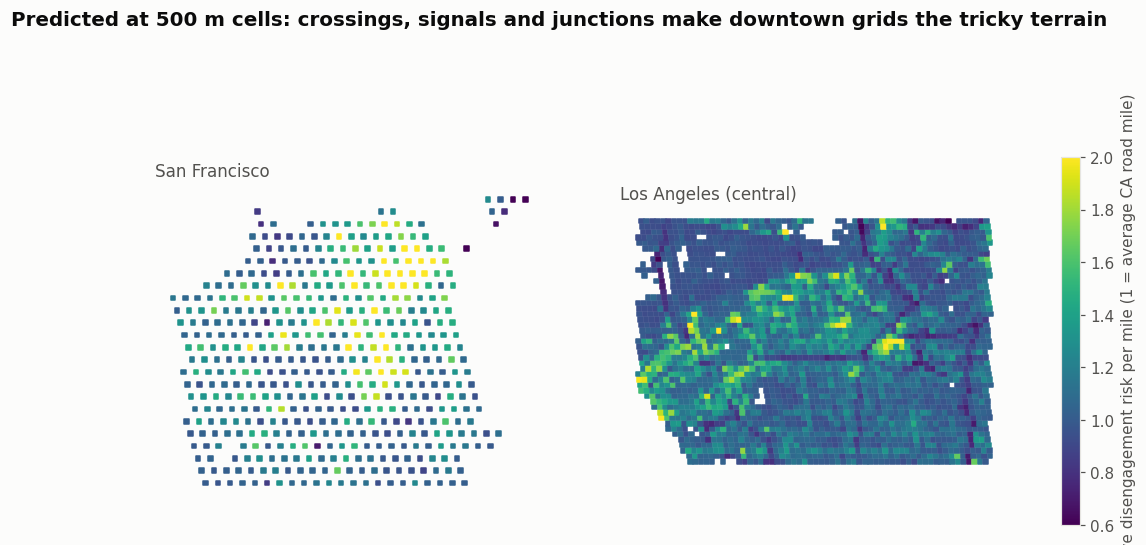

In [12]:
cl = res["cell"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2))
for ax, (name, box) in zip(axes, {"San Francisco": (-122.52, -122.35, 37.70, 37.82),
                                  "Los Angeles (central)": (-118.50, -118.15, 33.95, 34.15)}.items()):
    x = cl[(cl.lon.between(box[0], box[1])) & (cl.lat.between(box[2], box[3]))]
    s = ax.scatter(x.lon, x.lat, c=x.risk_multiplier, cmap="viridis", s=9, marker="s", vmin=0.6, vmax=2.0)
    ax.set_title(name, loc="left", fontsize=11, color=INK2); ax.set_aspect(1 / np.cos(np.radians(box[2])))
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
fig.colorbar(s, ax=axes, shrink=0.7, label="relative disengagement risk per mile (1 = average CA road mile)")
fig.suptitle("Predicted at 500 m cells: crossings, signals and junctions make downtown grids the tricky terrain",
             x=0.02, ha="left", fontsize=13, fontweight="600")
plt.savefig("figures/DIS_03_cells.png", dpi=160, bbox_inches="tight"); plt.show()

**Where the tricky terrain is.** Counties range from 0.80 (Lassen, Trinity, Modoc) to 1.50 for San Francisco
(90% range 1.16–3.46). Los Angeles County is 1.11 (1.05–1.32). Among cities with 100+ km of road, the
highest in the dashboard's counties are San Francisco 1.50, Santa Monica 1.44, Culver City 1.43, Redondo
Beach 1.40 and Palo Alto 1.36. Across the 3,145 tracts of San Francisco, Los Angeles and Santa Clara the
median is 1.09 and the 5th–95th percentile 0.87–1.61. Curbside activity is the largest term in 48% of
those tracts, signals and stop signs in 24%, crosswalks in 11%.

The ranges are wide where densities are extreme, because the dose-response is uncertain: the tract upper
bounds in downtown San Francisco reach up to 21×, which is what a linear response would give. Named stretches
make it concrete. Market Street in San Francisco (14 signals, 16 crossings and 22 junctions in 1.2 km) is
1.29× an average California road mile; Wilshire Boulevard in Los Angeles is 1.24×. These are the "tricky
terrain" the engineer asked for, at street level.

## 5 · Does the map mark places where AVs struggle?

Disengagements can't be located, so the map can't be checked against them directly. Two located AV
outcomes played no part in building it:

- **DMV OL 316 collision reports, every company, 2019–24**, re-geocoded against OpenStreetMap
  (notebook 07). These are tested on the tracts in the deployment footprint, within county, *per km of
  road*: a negative-binomial with county fixed effects and an offset for log road km.
- **Waymo's CPUC collisions per tract and quarter, 2025–26** (notebook 06's panel). Spatial 8-fold
  held-out deviance reduction is measured with and without each score, over a base of service maturity
  and road length.

Compared: revisions 1–3, the road class alone, each specialised model alone, and two reference points
(crossings per km, and the crash-risk model of notebook 06, which was *trained* on the CPUC collisions).

In [13]:
import avgap_place as P, avgap_osm as O, avgap_external as X
from avgap_coverage import tract_table
ol, alloc = D.located_crashes()
t, _ = tract_table()
t = t.merge(P.load_built_env(), on="GEOID", how="left")
t = O.add_road_features(P.add_model_features(t), O.tract_roads())
t["log_land"] = np.log(t.land_sqmi.clip(lower=0.01))
t = t.drop(columns=["road_km"]).merge(res["tract"][["road_km"]].rename_axis("GEOID").reset_index(), on="GEOID", how="left")
t["crashes"] = X.crash_counts(ol, alloc, t, mode="autonomous")
# the scores
ref = terr
T_ = terr.set_index("GEOID")
untied = {h: pd.DataFrame(0.0, index=["freeway", "surface"], columns=D.SITUATIONS).assign(**{"none stated": 1.0}) for h in ["x"]}["x"]
mid = 0.5 * fit["shares"]["stated"] + 0.5 * fit["shares"]["imputed"]
S = {"revision 3 (aggregated)": D.multipliers(T_, ref, fit["rho"], mid)[0],
     "revision 3, stated shares": D.multipliers(T_, ref, fit["rho"], fit["shares"]["stated"])[0],
     "revision 3, imputed shares": D.multipliers(T_, ref, fit["rho"], fit["shares"]["imputed"])[0],
     "revision 3, five mapped features only": D.multipliers(T_, ref, fit["rho"], mid, {k: D.TIED[k] for k in D.TIED_CORE})[0],
     "road class only (ratio from filed miles)": D.multipliers(T_, ref, fit["rho"], untied)[0]}
for s_ in [s for s in D.TIED if not s.endswith("(freeway)")]:
    one = untied.copy(); one.loc["surface", s_] = mid.loc["surface", s_]; one.loc["surface", "none stated"] = 1 - mid.loc["surface", s_]
    S[f"specialised: {s_}"] = D.multipliers(T_, ref, 1.0, one)[0]
for k, v in S.items():
    t[k] = t.GEOID.map(v)
for rev in (1, 2):
    t[f"revision {rev} (road length)"] = t.GEOID.map(pd.read_csv(f"outputs/tract_scores_disengagement_rev{rev}.csv", dtype={"GEOID": str}).set_index("GEOID").risk_multiplier)
t["crossings per km"] = t.n_crossings / t.road_km.clip(lower=0.1)
t["crash model (nb 06, trained on CPUC)"] = t.GEOID.map(pd.read_csv("outputs/tract_scores.csv", dtype={"GEOID": str}).set_index("GEOID").risk_index)
Lt = t[t.served_now].copy()
print(f"listed tracts: {len(Lt):,}; located autonomous-mode crashes inside them: {Lt.crashes.sum():.0f}")
order = ["revision 3 (aggregated)", "revision 3, stated shares", "revision 3, imputed shares",
         "revision 3, five mapped features only", "road class only (ratio from filed miles)"] + [k for k in S if k.startswith("specialised")] + \
        ["revision 1 (road length)", "revision 2 (road length)", "crossings per km", "crash model (nb 06, trained on CPUC)"]
cc = D.crash_check(Lt, {k: k for k in order})
cc.round(3)

listed tracts: 1,796; located autonomous-mode crashes inside them: 324


,within-county Spearman,Spearman per km,elasticity per km,95% CI,tracts,dAIC vs best
score,,,,,,
revision 3 (aggregated),0.327,0.451,3.286,2.66 to 3.91,1795,40.441
"revision 3, stated shares",0.296,0.424,5.135,4.04 to 6.23,1795,59.577
"revision 3, imputed shares",0.335,0.457,2.583,2.11 to 3.06,1795,33.447
"revision 3, five mapped features only",0.154,0.178,5.711,3.56 to 7.87,1795,109.316
road class only (ratio from filed miles),-0.095,-0.024,0.000,-2.70 to 2.70,1795,138.387
specialised: traffic control,0.119,0.122,14.164,8.59 to 19.73,1795,111.862
specialised: intersection turn,0.090,-0.010,35.823,-19.29 to 90.93,1795,136.755
specialised: pedestrian,0.246,0.268,30.107,22.65 to 37.56,1795,73.119
specialised: cyclist,0.270,0.220,79.731,55.75 to 103.71,1795,95.370


In [14]:
d = P.tract_quarter_panel(t)
d["log_road_km"] = np.log(d.road_km.clip(lower=0.1))
extra = {}
for k in ["revision 3 (aggregated)", "road class only (ratio from filed miles)", "revision 2 (road length)",
          "specialised: pedestrian", "specialised: traffic control", "specialised: intersection turn", "crossings per km"]:
    c = "log_" + k.replace(" ", "_").replace("(", "").replace(")", "").replace(",", "").replace(":", "")
    d[c] = np.log(d[k].clip(lower=1e-3))
    extra[k] = c
pc = D.panel_check(d, extra)
print(f"CPUC panel: {len(d):,} tract-quarters, {d.collisions.sum():,.0f} collisions")
pc.round(1)

CPUC panel: 10,176 tract-quarters, 1,330 collisions


held-out deviance reduction %,-,as published (offset),fitted weight
score,,,
crossings per km,NaN,22.4,25.0
maturity + road km,18.4,NaN,NaN
revision 2 (road length),NaN,12.4,18.1
revision 3 (aggregated),NaN,17.5,-37.0
road class only (ratio from filed miles),NaN,18.4,18.2
specialised: intersection turn,NaN,18.4,15.7
specialised: pedestrian,NaN,18.3,-30.4
specialised: traffic control,NaN,18.7,13.0


**DMV crashes (other companies, 2019–24; never used to build anything here).** In the 1,796 tracts in the
deployment footprint, revision 3 ranks autonomous-mode crashes per km of road at a within-county Spearman
of **0.45** (0.33 on raw counts). For comparison:
- revision 2: 0.04;
- revision 1: −0.26 (it ranked them backwards);
- crossings per km alone: 0.47;
- notebook 06's crash model, trained on Waymo's CPUC collisions: 0.43.

The extension matters: the five-feature version reaches 0.18. Curbside activity (POIs) carries most of the
gain; on its own it reaches 0.46. Curvature runs the wrong way (−0.11): curvy roads are residential and
rural, where few AV crashes happen. It stays in the model because lane-keeping takeovers are about curves,
not collisions; it barely moves the map.

**Waymo's CPUC collisions, 2025–26.** Used as published (an offset, nothing learned from collisions), the
map leaves held-out fit unchanged: 17.5% deviance reduction against 18.4% for service maturity and road
length alone. Crossings per km reach 22.4%. Within the footprint the ranking still agrees: Spearman per km
0.48 (dose-response scan below).

The map is built only from disengagement reports and OpenStreetMap, and it ranks where AV collisions
happen about as well as the best single feature, crossing density. That is the lesson of notebook 13
again: the tricky terrain is busy, pedestrian-dense, commercial streets.

### How strongly does risk grow with feature density?

The specialised models assume a situation's rate per mile grows with its feature's density raised to a
power β (the dose-response). β = 1 (linear) is the natural first guess. It means each signal passed is
another, equally risky chance to disengage. But downtown signal and shop densities are 50–100× those of
an average California road mile, so linear scaling puts downtown tracts at 20× and more. The scan below
sets β from 1 down to 0.25 and checks both crash records:

- ranking per km (Spearman), for the DMV crashes and Waymo's CPUC collisions summed over 2025–26;
- the CPUC panel with the map used as published (offset).

In [15]:
cp = d.groupby("GEOID").collisions.sum()
Lt["cpuc"] = Lt.GEOID.map(cp).fillna(0)
Lc = Lt[Lt.GEOID.isin(cp.index)].copy()
rows, pan = [], {}
for beta in [1.0, 0.75, 0.5, 0.35, 0.25]:
    m = D.multipliers(T_, ref, fit["rho"], mid, beta=beta)[0]
    k = f"beta {beta}"
    for frame in (Lt, Lc, d):
        frame[k] = frame.GEOID.map(m)
    a, b = D.crash_check(Lt, {k: k}), D.crash_check(Lc, {k: k}, y="cpuc")
    d["log_" + k.replace(" ", "_").replace(".", "p")] = np.log(d[k].clip(lower=1e-3))
    sc_t = m.reindex(t_out[t_out.county.isin(D.SCOPE_COUNTIES)].GEOID)
    rows.append({"beta": beta, "DMV Spearman per km": a.iloc[0]["Spearman per km"], "DMV elasticity": a.iloc[0]["elasticity per km"],
                 "CPUC Spearman per km": b.iloc[0]["Spearman per km"], "CPUC elasticity": b.iloc[0]["elasticity per km"],
                 "scope tracts: 95th pct": sc_t.quantile(.95), "max": sc_t.max()})
    pan[k] = "log_" + k.replace(" ", "_").replace(".", "p")
bs = pd.DataFrame(rows).set_index("beta")
bs["CPUC panel, as published (%)"] = D.panel_check(d, pan)["as published (offset)"].reindex([f"beta {b}" for b in bs.index]).to_numpy()
print(f"CPUC panel base (maturity + road km): {pc.loc['maturity + road km', '-']:.1f}%; product beta = {D.BETA}, 90% range draws beta from {D.BETA_RANGE}")
bs.round(3)

CPUC panel base (maturity + road km): 18.4%; product beta = 0.5, 90% range draws beta from (0.25, 1.0)


,DMV Spearman per km,DMV elasticity,CPUC Spearman per km,CPUC elasticity,scope tracts: 95th pct,max,"CPUC panel, as published (%)"
beta,,,,,,,
1.00,0.465,1.161,0.504,1.894,3.656,21.273,-3.090
0.75,0.459,1.807,0.498,2.924,2.243,6.862,11.871
0.50,0.451,3.286,0.484,5.173,1.547,2.636,17.458
0.35,0.432,5.012,0.463,7.705,1.298,1.731,18.474
0.25,0.401,6.481,0.434,9.846,1.181,1.398,18.673


The ranking barely depends on β (DMV per km 0.465 at β = 1, 0.451 at 0.5, 0.401 at 0.25), but the scale
does. With β = 1, downtown tracts reach 21× and the CPUC panel falls to −3.1%. With β = 0.5 the largest
scope tract is 2.6× and the panel is back near its base (17.5%). The two records pull in opposite
directions on scale: DMV crashes per km grow with the map at elasticity 1.16 when β = 1, and CPUC
collisions at 1.89. So the product uses **β = 0.5**. The 90% range draws β uniformly from 0.25 to 1, so
the scale uncertainty stays visible.

The CPUC panel informed this choice, so it isn't a clean held-out test of β. The DMV ranking is almost
unaffected by β and remains one.

In [16]:
big = fit["report_table"].company.value_counts().head(8).index
ml = D.map_loco(fit["report_table"], T_, ref, fit["rho"], big)
print("situation shares without each of the 8 largest filers -> tract map vs. the full map (all CA tracts):")
ml.round(3)

situation shares without each of the 8 largest filers -> tract map vs. the full map (all CA tracts):


,left out,reports left out,Spearman with full map,top tenth kept
0,May Mobility,20694,0.999,0.991
1,Apple,10254,0.998,0.976
2,Beep,9159,0.935,0.807
3,Ghost Autonomy,1833,1.000,0.998
4,AImotive,1795,1.000,0.992
5,Toyota,1746,0.996,0.954
6,Mercedes-Benz,1481,1.000,0.999
7,Motional,1048,1.000,0.999


**No single company drives the map.** Dropping any of the eight largest filers from the situation shares
leaves the tract map at Spearman 0.93 or higher with the full one. The largest change comes from dropping
Beep (0.935; 81% of the top tenth kept), whose obstruction reports are a large part of the curbside model.

In [17]:
# specificity: does each specialised layer track its own kind of crash better than the rest?
layers = {s_: f"specialised: {s_}" for s_ in [s for s in D.TIED if not s.endswith("(freeway)")]}
sc_ = D.situation_check(Lt, ol, alloc, layers)
sit = D.crash_situations()
print(f"located DMV crashes with a road situation from the two LLMs: {sit.notna().sum()} "
      f"(autonomous mode, in listed tracts: {X.crash_counts(ol[sit.reindex(ol.index).notna()], alloc, Lt, mode='autonomous').sum():.0f})")
print(sit.reindex(ol[ol['mode'] == 'autonomous'].index).value_counts().to_string())
sc_.round(3)

located DMV crashes with a road situation from the two LLMs: 645 (autonomous mode, in listed tracts: 324)
probs
traffic control              91
intersection turn            85
obstruction                  60
other vehicle                52
cyclist                      21
lane change or merge         18
none stated                  15
lane keeping                  7
pedestrian                    6
construction or emergency     2


,located crashes naming it,Spearman per km: its own crashes,Spearman per km: all other crashes
situation,,,
traffic control,85.0,0.053,0.120
intersection turn,77.0,0.116,-0.052
pedestrian,6.0,0.089,0.253
cyclist,19.0,0.063,0.222
lane change or merge,13.0,0.096,0.267
obstruction,55.0,0.179,0.437
lane keeping,6.0,0.038,-0.105


**The specialised layers mostly mark busy streets, not their own kind of crash.** The same LLM question
asked of the collision narratives labels 645 DMV crashes; 324 are autonomous-mode crashes in the
footprint. Only the junction layer tracks crashes of its own situation (intersection turns: Spearman per km
0.12, against −0.05 for all other crashes). The traffic-control, pedestrian, cyclist, merge and curbside
layers each rank *other* crashes better than their own. Most of these situations have few located crashes
(6 pedestrian, 13 merge, 19 cyclist), so this is weak evidence either way. But it means the layers'
labels describe what the disengagement reports say happens there, not a separately validated risk.

In [18]:
# the validation numbers the dashboard quotes (outputs/disengagement_model.json)
v = {"listed_tracts": int(len(Lt)), "crashes": round(float(Lt.crashes.sum()), 1),
     "spearman_rev3": round(float(cc.loc["revision 3 (aggregated)", "within-county Spearman"]), 3),
     "spearman_per_km_rev3": round(float(cc.loc["revision 3 (aggregated)", "Spearman per km"]), 3),
     "spearman_rev2": round(float(cc.loc["revision 2 (road length)", "within-county Spearman"]), 3),
     "spearman_rev1": round(float(cc.loc["revision 1 (road length)", "within-county Spearman"]), 3),
     "spearman_crossings": round(float(cc.loc["crossings per km", "within-county Spearman"]), 3),
     "spearman_crash_model": round(float(cc.loc["crash model (nb 06, trained on CPUC)", "within-county Spearman"]), 3),
     "elasticity_rev3": round(float(cc.loc["revision 3 (aggregated)", "elasticity per km"]), 2),
     "cpuc_base": round(float(pc.loc["maturity + road km", "-"]), 1),
     "cpuc_rev3_offset": round(float(pc.loc["revision 3 (aggregated)", "as published (offset)"]), 1),
     "map_loco_min_spearman": round(float(ml["Spearman with full map"].min()), 3)}
v["spearman_per_km_rev2"] = round(float(cc.loc["revision 2 (road length)", "Spearman per km"]), 3)
v["spearman_per_km_crossings"] = round(float(cc.loc["crossings per km", "Spearman per km"]), 3)
v["text"] = (f"Checked against an independent record: in the {v['listed_tracts']:,} tracts AVs drove, the map ranks "
             f"{v['crashes']:.0f} DMV-reported autonomous-mode collisions (2019–24) per km of road within county at "
             f"Spearman {v['spearman_per_km_rev3']:.2f} (the road-length version it replaces: {v['spearman_per_km_rev2']:.2f}; "
             f"crossing density alone: {v['spearman_per_km_crossings']:.2f}). No collision data were used to build it.")
m = D.model_json(fit, validation=v)
print(m["validation"]["text"])

Checked against an independent record: in the 1,796 tracts AVs drove, the map ranks 324 DMV-reported autonomous-mode collisions (2019–24) per km of road within county at Spearman 0.45 (the road-length version it replaces: 0.04; crossing density alone: 0.47). No collision data were used to build it.


In [19]:
r1 = pd.read_csv("outputs/tract_scores_disengagement_rev1.csv", dtype={"GEOID": str}).set_index("GEOID").risk_multiplier
r2 = pd.read_csv("outputs/tract_scores_disengagement_rev2.csv", dtype={"GEOID": str}).set_index("GEOID").risk_multiplier
r3 = t_out.set_index("GEOID").risk_multiplier
sc_ids = t_out[t_out.county.isin(D.SCOPE_COUNTIES)].GEOID
j = pd.concat([r1, r2, r3], axis=1, keys=["rev1", "rev2", "rev3"]).reindex(sc_ids).dropna()
print("Spearman between revisions, SF + LA + Santa Clara tracts:")
print(j.corr(method="spearman").round(2).to_string())
top3 = set(j.rev3.nlargest(len(j) // 10).index)
print(f"top tenth by revision 3 also in revision 2's top tenth: {len(top3 & set(j.rev2.nlargest(len(j) // 10).index)) / len(top3):.0%}")

Spearman between revisions, SF + LA + Santa Clara tracts:
      rev1  rev2  rev3
rev1  1.00  0.62 -0.41
rev2  0.62  1.00 -0.26
rev3 -0.41 -0.26  1.00
top tenth by revision 3 also in revision 2's top tenth: 1%


Revision 3 is a different map from revisions 1 and 2. In the dashboard's counties its tract ranks
correlate −0.26 with revision 2 and −0.41 with revision 1, and 1% of its top tenth is in revision 2's top
tenth. The earlier revisions ranked freeway-heavy tracts highest. Revision 3 ranks dense street grids
highest, and only revision 3 agrees with where AVs actually crashed.

## 6 · What changes for the dashboard

- **Units.** Relative disengagement risk per mile (1 = an average California road mile), with a 90%
  range, plus reports per 1,000 miles at the 2024 median company's rate (0.50). Each specialised model
  shows its sample size, the reports that name its situation.
- **Levels.** Predicted at 500 m grid cells and named road stretches; shown by county, city and tract,
  with a "500 m grid" map mode.
- **Files.** `outputs/tract_scores_disengagement.csv` keeps revision 1's columns and adds per-1,000-mile
  rates, terms and the top feature. New files: `disengagement_areas.csv` (county and city),
  `disengagement_cells.csv`, `disengagement_stretches.csv`, `disengagement_model.json` (headline numbers).
- **Wording.**
  - Say "disengagement risk per mile", "relative to an average California road mile", "reports name".
  - Don't say "freeways are safer". Say "freeway-type roads are not riskier per mile driven".
  - Don't call a layer validated on its own crash type; only the junction layer showed that.
  - Industry-wide: Waymo is under 2% of the reports. The 2020–24 testing era is a closed record.

**What would make it stronger.**
- Miles by road type from any company would replace the calibrated range with a measurement.
- A located sample of disengagements (CPUC or company-shared) would let the specialised models be checked
  against disengagements instead of collisions.
- Two annotators labelling the road situation of 100 reports would put a human κ next to the LLMs'.